# 錯誤趨勢分析

[error_analysis.md](error_analysis.md) 的程式與完整輸出。章節編號與 error_analysis.md 相同;結論的文字說明以 error_analysis.md 為準。

## 目錄

- [載入資料](#載入資料)
- **A. 什麼情況下容易錯**
  - [A1 片段長度](#A1-片段長度:正確片段越短,越容易答錯?)
  - [A2 動作類型](#A2-動作類型:哪些動詞特別難?)
  - [A3 一次問幾題與題目位置](#A3-一次問幾題與題目位置)
- **B. 錯的時候錯在哪**
  - [B1 錯誤很穩定,不是碰運氣](#B1-錯誤很穩定,不是碰運氣)
  - [B2 錯得多遠,選到什麼](#B2-錯得多遠,選到什麼)
  - [B3 偏好最長的選項](#B3-偏好最長的選項)
  - [B4 字母位置偏差](#B4-字母位置偏差)

## 結論摘要

| | 發現的趨勢 | 檢定 | 能證明 | 不能證明 |
|---|---|---|---|---|
| **A1 片段長度** | 正確片段越短越容易答錯(<0.5 秒 18% → >8 秒 62.5%) | Spearman 相關(ρ = 0.23, p ≈ 5e-37);logistic 迴歸 + 按影片 bootstrap(長度加倍,勝算 ×1.53,95% CI 1.41–1.68) | 長度和對錯有穩定關聯,不是偶然,且不因同一影片的題目相關而消失 | 原因是 2 FPS 取樣(需用較高 FPS 重跑短片段) |
| **A2 動作類型** | 同樣片段長度下,動詞仍有差:pick、move、transfer 接近亂猜;rinse 最容易(相對 pick 勝算 ×5.6)、place ×2.6 | 分層熱力圖(動詞 × 長度);logistic 迴歸 `correct ~ log2(長度) + 動詞`,概似比檢定 χ² = 83.5, p ≈ 7e-16(只含題數 ≥ 60 的 7 個動詞) | 控制片段長度後,動詞仍與準確率有關聯,不能只用「片段短」解釋 | 原因是動作本身(如動作快、位移大);動詞也綁著重複出現、干擾選項相似度、場景等因素 |
| **A3 一次問幾題與題目位置** | 16 題以上的 prompt 才退步(1 / 4 / 8 / 16 / 32 題:33.0 / 34.9 / 35.0 / 30.7 / 26.7%);控制位置後,批次大小沒有額外影響 | 條件式 logistic 迴歸(題目固定效果)+ 按報告 bootstrap:離結尾距離每加倍,勝算 ×0.81(95% CI 0.75–0.87);位置 × 批次 32 題交互作用 p = 0.75 | 退步跟著「離 prompt 結尾的距離」走,同樣距離下批次大小不再拉低準確率 | 為什麼靠近結尾比較準(靠近格式說明 / 作答處分不開);題序沒打亂過,需反轉順序重跑 |
| **B1 錯誤的穩定性** | 同一題在 5 個條件下反覆答錯:五次全錯 821 題(獨立下期望 336),全對 164 題(期望 8);全錯題中 162 題五次選同一個錯誤字母(亂選期望約 3) | 排列檢定(洗牌各條件對錯,p ≤ 0.0005);二項檢定「五次選同一錯誤字母」(p ≈ 2e-216) | 可以拒絕「各次對錯獨立」和「答錯時均勻亂選」,答錯不是碰運氣,錯誤集中在特定題目與特定錯誤選項 | 模型有固定的錯誤想法或被選項內容吸引(五個條件共用同一影片與選項,不是獨立重複;模型對長選項、特定字母的共同偏好也會造成集中) |
| **B2 錯得多遠** | 答錯時選到的片段離正解中位 33.5 秒(約影片長度 7%),不是「差一點」 | 描述統計(秒數與相對距離);「選到最近的錯誤選項」二項檢定 30.1% vs 25%,p ≈ 4e-7 | 錯誤多半是選到遠處的另一個動作;有輕微偏向靠近正解的選項(+5 個百分點) | 模型是因為選項「真實」才選它(未比較真實與非真實干擾);相對距離的分母是模型看到的片段長度,不是整支影片 |
| **B3 選項長度** | 答錯時偏好選最長的錯誤選項(31.1% vs 隨機 25%) | 二項檢定(p ≈ 1e-9);整體選最長 27.5% vs 20%(p ≈ 5e-22) | 模型挑錯誤選項不是均勻隨機,偏向較長者,且隨長度排名單調上升 | 原因是「選項長度」本身(可能是與正解的距離、畫面量等相關因素) |
| **B4 字母位置** | E1 偏愛 B(27.1% vs 標準答案 19.6%)、少選 A;批次條件改為少選 E | 卡方適合度檢定(E1: χ² = 126,其他 22–37,p 皆 < 0.001);對 B 的二項檢定(p ≈ 5e-22) | 模型選字母的分布和標準答案不同,且偏差會隨提問方式改變 | 原因是字母本身(選項順序沒打亂過,位置與內容綁在一起) |

共同限制:p 值假設每題獨立,但同一影片的題目彼此相關,所以 p 偏樂觀(只有 A1、A3 做了按影片 / 報告 bootstrap);全部都是相關,不是因果。


# 載入資料

共用的函式與 E1 定位題資料(`d`),A1、A2 會用到。

In [1]:
import re
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from scipy import stats, optimize

sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# 正確片段長度 = 標準答案選項的「結束時間 - 開始時間」(秒)
def seconds(text):
    t = [int(h)*3600 + int(m)*60 + float(s) for h, m, s in re.findall(r"(\d+):(\d+):([\d.]+)", text)]
    return t[1] - t[0]

d = pd.read_csv("data/per_field.csv")
d = d[(d.experiment == "E1") & (d.category == "fine_grained_action_localization")].copy()
d["dur"] = d.target_text.map(seconds)
d["y"] = d.correct.astype(int)
d["type"] = d.category.map({
    "fine_grained_action_localization": "loc",
    "fine_grained_how_recognition": "how",
    "fine_grained_why_recognition": "why",
    "ingredient_ingredient_weight": "weight"})
print(len(d), "題,整體準確率", round(d.y.mean(), 3))

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


2861 題,整體準確率 0.324


In [2]:
d.head(3)

,report_id,field_id,call_id,outcome,correct,predicted,predicted_text,target,target_text,detail,experiment,category,matched_localization,e6_common_target,source_video,dur,y,type
0,hdepic-dense-001,loc_445,hdepic-dense-001::field=loc_445,incorrect,False,C,this clip from 0:00:50.103 to 0:00:51.814,E,this clip from 0:00:52.384 to 0:00:52.853,NaN,E1,fine_grained_action_localization,False,False,/home/azureuser/datasets/hd-epic/Videos/P09/P0...,0.469,0,loc
1,hdepic-dense-001,loc_516,hdepic-dense-001::field=loc_516,correct,True,A,this clip from 0:03:22.444 to 0:03:25.293,A,this clip from 0:03:22.444 to 0:03:25.293,NaN,E1,fine_grained_action_localization,True,False,/home/azureuser/datasets/hd-epic/Videos/P09/P0...,2.849,1,loc
2,hdepic-dense-001,loc_645,hdepic-dense-001::field=loc_645,incorrect,False,A,this clip from 0:01:01.293 to 0:01:02.853,C,this clip from 0:01:00.314 to 0:01:00.834,NaN,E1,fine_grained_action_localization,False,False,/home/azureuser/datasets/hd-epic/Videos/P09/P0...,0.520,0,loc


# A. 什麼情況下容易錯

## A1 片段長度:正確片段越短,越容易答錯?

對應 [error_analysis.md](error_analysis.md) A1。
只用 E1 的定位題(一題一問,5 選 1,亂猜 = 20%)。

### 圖:各片段長度區間的準確率

每個點是該區間的準確率,誤差線是 95% 信賴區間(bootstrap)。虛線是亂猜的 20%。

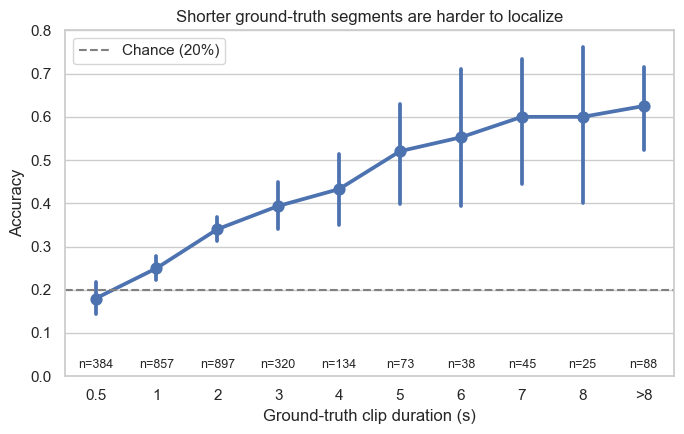

In [3]:
# labels = ["<0.5", "0.5-1", "1-2", "2-4", "4-8", ">8"]
labels = ["0.5", "1", "2", "3", "4", "5", "6", "7", "8", ">8"]
d["bin"] = pd.cut(d.dur, [0, .5, 1, 2, 3, 4, 5, 6, 7, 8, np.inf], right=False, labels=labels)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.pointplot(data=d, x="bin", y="y", errorbar=("ci", 95), seed=0, ax=ax)
ax.axhline(0.2, ls="--", color="gray", label="Chance (20%)")
for i, n in enumerate(d.groupby("bin", observed=True).size()):
    ax.text(i, 0.02, f"n={n}", ha="center", fontsize=9)
ax.set(xlabel="Ground-truth clip duration (s)", ylabel="Accuracy", ylim=(0, 0.8),
       title="Shorter ground-truth segments are harder to localize")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### 統計檢定

1. **Spearman 相關**:片段長度和對錯是否有單調關係?(一行,不用分組,不受切法影響)
2. **logistic 迴歸斜率 + 按影片 bootstrap**:長度每加倍,答對的勝算變多少?
   同一部影片的題目彼此不獨立,所以整部影片一起重抽,信賴區間才不會太樂觀。

In [4]:
rho, p = stats.spearmanr(d.dur, d.y)
print(f"Spearman rho = {rho:.3f}, p = {p:.2e}")

x = np.log2(d.dur.values)

def slope(x, y):
    # 對錯 ~ log2(片段長度) 的 logistic 迴歸斜率(最大概似)
    nll = lambda b: -(y*(b[0]+b[1]*x) - np.log1p(np.exp(b[0]+b[1]*x))).sum()
    return optimize.minimize(nll, [0, 0]).x[1]

rng = np.random.default_rng(0)
groups = [g for _, g in d.groupby("source_video")]
boot = []
for _ in range(1000):
    s = pd.concat([groups[i] for i in rng.integers(0, len(groups), len(groups))])
    boot.append(slope(np.log2(s.dur.values), s.y.values))

b = slope(x, d.y.values)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"片段長度每加倍,勝算 x{np.exp(b):.2f}  (95% CI x{np.exp(lo):.2f} ~ x{np.exp(hi):.2f}, {len(groups)} 部影片)")

Spearman rho = 0.234, p = 5.11e-37


片段長度每加倍,勝算 x1.53  (95% CI x1.41 ~ x1.68, 76 部影片)


- Spearman: 答對那組的片段長度排名,是否整體比答錯那組高。ρ = 0.234 可以換算成 AUC ≈ 0.5 + ρ·(某個比例) 大約 0.6 出頭,也就是隨機挑一題答對、一題答錯,答對那題片段比較長的機率約 60%。
- Logistic: 正確片段長度每變成兩倍,模型答對的「勝算」(odds)平均變成 1.53 倍。
- 這只證明「長度和對錯有穩定關聯」,不證明原因是 2 FPS 取樣。要驗證原因,需要對短片段用較高 FPS 重跑。

### 圖:依題型分組,不同片段長度的準確率(折線圖)

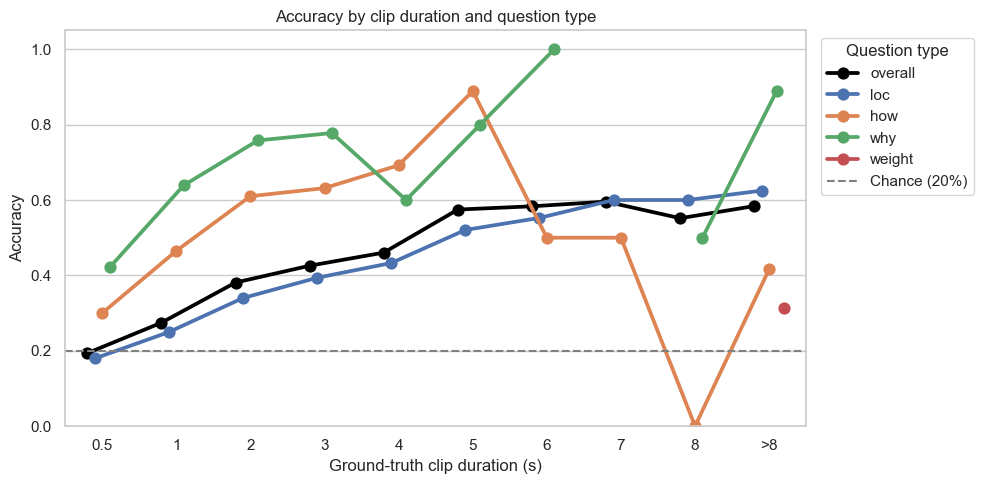

bin     0.5    1    2    3    4   5   6   7   8  >8
type                                               
loc     384  857  897  320  134  73  38  45  25  88
how      10   43   59   19   13   9   6   2   2  12
why      19   36   62   18    5   5   4   0   2   9
weight    0    0    0    0    0   0   0   0   0  16


In [5]:
import gzip, json

seg = {}
with gzip.open("data/frozen_requests/E1.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line)
        m = re.search(r"\(segment: ([\d:.]+) - ([\d:.]+) of this clip\)", r["user"])
        seg[r["call_id"]] = seconds(f"{m.group(1)} {m.group(2)}")

a = pd.read_csv("data/per_field.csv")
a = a[a.experiment == "E1"].copy()
a["y"] = a.correct.astype(int)
a["type"] = a.category.map({
    "fine_grained_action_localization": "loc",
    "fine_grained_how_recognition": "how",
    "fine_grained_why_recognition": "why",
    "ingredient_ingredient_weight": "weight"})
a["dur"] = a.call_id.map(seg)
loc = a.type == "loc"
a.loc[loc, "dur"] = a.loc[loc, "target_text"].map(seconds)  # loc 用正確選項時段
a["bin"] = pd.cut(a.dur, [0, .5, 1, 2, 3, 4, 5, 6, 7, 8, np.inf], right=False, labels=labels)
order = ["overall", "loc", "how", "why", "weight"]
plot = pd.concat([a, a.assign(type="overall")])  # 整體 = 四種題型合併

fig, ax = plt.subplots(figsize=(10, 5))
sns.pointplot(data=plot, x="bin", y="y", hue="type", hue_order=order, errorbar=None,
              dodge=0.4, palette=["black"] + sns.color_palette("deep", 4), ax=ax)
ax.axhline(0.2, ls="--", color="gray", label="Chance (20%)")
ax.set(xlabel="Ground-truth clip duration (s)", ylabel="Accuracy", ylim=(0, 1.05),
       title="Accuracy by clip duration and question type")
ax.legend(title="Question type", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print(a.pivot_table(index="type", columns="bin", values="y", aggfunc="size", observed=False).loc[["loc", "how", "why", "weight"]])

## A2 動作類型:哪些動詞特別難?

對應 [error_analysis.md](error_analysis.md) A2。
動詞和片段長度互相混在一起(例如 pick 的片段通常很短),所以要一起看:

1. **分層熱力圖**:動詞 × 片段長度(3 段)的準確率,格內同時標題數 n。只保留題數 ≥ 60 的動詞。
2. **羅吉斯迴歸**:`correct ~ log2(片段秒數) + 動詞`。問題是:控制片段長度之後,動詞還有沒有效應?
   - 用概似比檢定(LR test)比較「有動詞」和「沒動詞」兩個模型,得到一個 p 值回答「動詞整體有沒有用」。
   - 各動詞的勝算比(OR)以 pick 為基準:OR > 1 代表同樣長度下比 pick 容易答對。

動詞取自題目 `<動詞 名詞>` 的動詞,資料與 A1 的 E1 定位題相同。

7 verbs, 1732/2861 questions kept


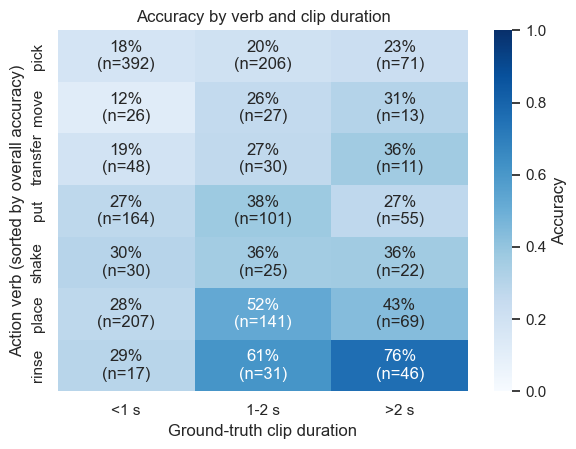

log_dur OR per doubling of duration = 1.37
LR test (add verb): chi2 = 83.5, df = 6, p = 6.9e-16
Odds ratio vs 'pick' (same duration):
             OR      p
move      1.006  0.985
transfer  1.308  0.322
put       1.821  0.000
shake     1.921  0.013
place     2.615  0.000
rinse     5.574  0.000


In [6]:
import statsmodels.formula.api as smf

# d["verb"] 可能已在前面建立;沒有的話這裡補上
if "verb" not in d:
    verb = {}
    with gzip.open("data/frozen_requests/E1.jsonl.gz", "rt") as f:
        for line in f:
            r = json.loads(line)
            verb[r["call_id"]] = re.search(r"<(\w+)", r["user"]).group(1)
    d["verb"] = d.call_id.map(verb)

keep = d.verb.value_counts()
keep = keep[keep >= 60].index
V = d[d.verb.isin(keep)].copy()
V["verb"] = V.verb.astype(object)  # patsy 不認新的 string dtype
V["bin3"] = pd.cut(V.dur, [0, 1, 2, np.inf], right=False, labels=["<1 s", "1-2 s", ">2 s"])
print(f"{V.verb.nunique()} verbs, {len(V)}/{len(d)} questions kept")

# 1) 分層熱力圖
acc = V.pivot_table(index="verb", columns="bin3", values="y", aggfunc="mean", observed=True)
cnt = V.pivot_table(index="verb", columns="bin3", values="y", aggfunc="size", observed=True)
order = V.groupby("verb").y.mean().sort_values().index
acc, cnt = acc.loc[order], cnt.loc[order]
labels = acc.map(lambda x: "" if pd.isna(x) else f"{x:.0%}") + "\n(n=" + cnt.fillna(0).astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(6, 0.45 * len(acc) + 1.5))
sns.heatmap(acc, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "Accuracy"}, ax=ax)
ax.set(xlabel="Ground-truth clip duration", ylabel="Action verb (sorted by overall accuracy)",
       title="Accuracy by verb and clip duration")
plt.tight_layout(); plt.show()

# 2) 羅吉斯迴歸 + 概似比檢定
V["log_dur"] = np.log2(V.dur)
ref = V.verb.value_counts().index[0]  # 基準 = 題數最多的動詞
m0 = smf.logit("y ~ log_dur", V).fit(disp=0)
m1 = smf.logit(f"y ~ log_dur + C(verb, Treatment('{ref}'))", V).fit(disp=0)
lr = 2 * (m1.llf - m0.llf); df = m1.df_model - m0.df_model
print(f"log_dur OR per doubling of duration = {np.exp(m0.params['log_dur']):.2f}")
print(f"LR test (add verb): chi2 = {lr:.1f}, df = {int(df)}, p = {stats.chi2.sf(lr, df):.2g}")

res = pd.DataFrame({"OR": np.exp(m1.params), "p": m1.pvalues}).iloc[1:-1]  # 去掉截距與 log_dur
res.index = [i.split("[T.")[1].rstrip("]") for i in res.index]
print(f"Odds ratio vs '{ref}' (same duration):")
print(res.sort_values("OR").round(3))

- 概似比檢定 p ≈ 7e-16:控制片段長度後,加入動詞仍然顯著改善模型,所以動詞效應不能完全用「片段長短」解釋。
- 以 pick 為基準、同樣長度下:rinse 容易答對 ≈ 5.6 倍、place ≈ 2.6 倍、put 與 shake ≈ 1.8–1.9 倍;move 和 transfer 與 pick 沒有顯著差異(p 0.99 和 0.32),它們和 pick 一樣接近亂猜。
- 限制:(1) 勝算比是相對 pick,不是相對平均;(2) 迴歸假設長度效應對所有動詞相同(沒有放交互作用),但熱力圖顯示 place 不是單調上升;(3) 同一影片的題目不獨立,p 偏樂觀;(4) 動詞可能混著干擾選項相似度或影片場景,只能說有關聯,不能說動作本身造成。

## A3 一次問幾題與題目位置

對應 [error_analysis.md](error_analysis.md) A3。

先用簡單的分段比較看退步出現在哪(A3-1),再用迴歸把批次大小和位置分開(A3-2,error_analysis.md 的數字來自這裡)。

### A3-1 初步:依 32 題清單位置分 4 段
並加入 E2–E4(每次問 4 / 8 / 16 題)一起比較。

**為什麼可以比**:已核對 73 份報告,E2–E5 都是**同樣的 32 題、同樣順序**。E5 是一個 32 題的 prompt;E4 把它依序切成 2 批 16 題,E3 切成 4 批 8 題,E2 切成 8 批 4 題。所以每題在 E1–E5 都有成績,位置(第幾題)也固定。

**怎麼比**:不同位置的題目難度不同,不能直接比各段準確率。改比「變化量 = 該條件的對錯 − 同一題在 E1(一題一問)的對錯」,再依題目在 32 題中的位置分 4 段(1–8、9–16、17–24、25–32)取平均。區間用「整份報告(影片)重抽」的 bootstrap(5000 次),因為同一份報告的題目不獨立。

**圖**:橫軸是每次問幾題(1 / 4 / 8 / 16 / 32),縱軸是準確率。每條線都是**同一組題目**:黑粗線是全部 2,336 題,藍色細線是把這些題依它們在 32 題清單裡的位置分成 4 組。印出的表是相對 E1 的變化量與區間。

Change in accuracy vs E1, percentage points [95% CI, bootstrap over 73 reports]
           E2 (4/prompt)      E3 (8/prompt)      E4 (16/prompt)      E5 (32/prompt)
1-8    +3.3 [-0.5, +7.0]  +0.3 [-3.3, +3.9]  -5.3 [-10.3, -0.5]  -7.7 [-12.5, -2.9]
9-16   +1.5 [-1.9, +5.0]  +4.3 [-0.2, +8.6]   +1.2 [-3.1, +5.3]  -9.6 [-14.2, -5.0]
17-24  +1.5 [-2.7, +6.0]  +1.2 [-2.7, +5.1]  -6.5 [-10.8, -2.2]  -7.0 [-11.5, -2.6]
25-32  +1.4 [-2.1, +4.6]  +2.2 [-2.1, +6.5]   +1.5 [-2.7, +6.0]   -1.0 [-5.8, +3.9]
Questions per prompt          1      4      8      16     32
Group                                                       
All 2,336 questions        0.330  0.349  0.350  0.307  0.267
Questions 1-8 of the list  0.348  0.380  0.351  0.295  0.271
Questions 17-24            0.337  0.353  0.349  0.272  0.267
Questions 25-32            0.310  0.324  0.332  0.325  0.300
Questions 9-16             0.325  0.341  0.368  0.337  0.229


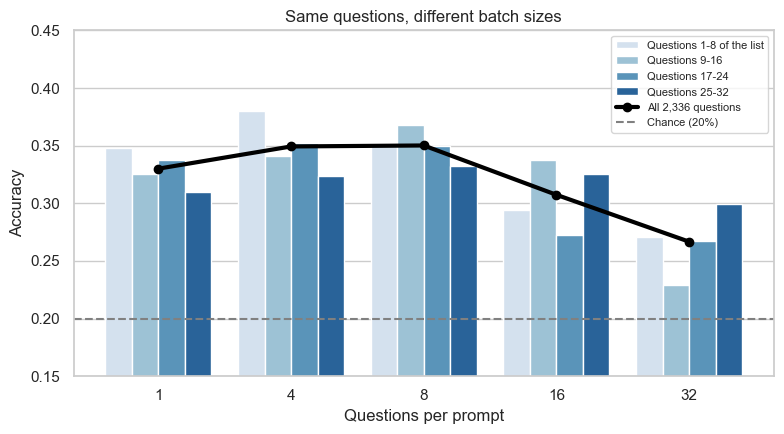

E4: non-last-8 minus last-8 = -7.3 pp  [95% CI -11.8, -3.0]


E5: non-last-8 minus last-8 = -7.1 pp  [95% CI -12.2, -2.2]


In [7]:
S7 = pd.read_csv("data/per_field.csv")
S7 = S7[(S7.category == "fine_grained_action_localization") & S7.matched_localization & S7.experiment.isin(["E1", "E2", "E3", "E4", "E5"])]
S7 = S7.assign(y=S7.correct.astype(int))

# 題目在 32 題中的位置 = 它在 E5 那個 prompt 裡出現的順序
order = {}
with gzip.open("data/frozen_requests/E5.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line)
        for i, fid in enumerate(re.findall(r"\[field_id: (\w+)\]", r["user"])):
            order[(r["report_id"], fid)] = i

Y = S7.pivot(index=["report_id", "field_id"], columns="experiment", values="y")
Y["pos"] = [order[k] for k in Y.index]
Y["block"] = Y.pos // 8                                        # 0..3 = 第 1–8、9–16、17–24、25–32 題
size = {"E2": 4, "E3": 8, "E4": 16, "E5": 32}
for e, n in size.items():
    Y[f"d_{e}"] = Y[e] - Y.E1                                  # 變化量
    Y[f"w_{e}"] = (Y.pos % n) // 8                             # 在自己 prompt 裡的位置段(0 = 前 8 題)

# 按報告彙總,方便 bootstrap:每份報告 x 條件 x 位置段 的變化量總和(每格 8 題)
rep = Y.reset_index().groupby(["report_id", "block"])[[f"d_{e}" for e in size]].sum()
A = rep.to_numpy().reshape(-1, 4, 4)                           # 報告 x 位置段 x 條件
rng = np.random.default_rng(0)
boot = np.array([A[rng.integers(0, len(A), len(A))].sum(0) / (8 * len(A)) for _ in range(5000)])  # 5000 x 位置段 x 條件
mean = A.sum(0) / (8 * len(A))
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

blocks = ["1-8", "9-16", "17-24", "25-32"]
tab = pd.DataFrame({f"{e} ({n}/prompt)": [f"{mean[b, j]*100:+.1f} [{lo[b, j]*100:+.1f}, {hi[b, j]*100:+.1f}]" for b in range(4)]
                    for j, (e, n) in enumerate(size.items())}, index=blocks)
print("Change in accuracy vs E1, percentage points [95% CI, bootstrap over", len(A), "reports]")
print(tab.to_string())

# 圖:同一組題目,每次問 1 / 4 / 8 / 16 / 32 題時的準確率(每條線都是同樣的題目)
conds = {"E1": 1, "E2": 4, "E3": 8, "E4": 16, "E5": 32}
groups = ["Questions 1-8 of the list", "Questions 9-16", "Questions 17-24", "Questions 25-32"]
long = pd.concat([pd.DataFrame({"Questions per prompt": n, "Accuracy": Y.groupby("block")[e].mean().values, "Group": groups})
                  for e, n in conds.items()] +
                 [pd.DataFrame({"Questions per prompt": [n], "Accuracy": [Y[e].mean()], "Group": ["All 2,336 questions"]})
                  for e, n in conds.items()])
print(long.pivot(index="Group", columns="Questions per prompt", values="Accuracy").round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
parts = long[long.Group != "All 2,336 questions"]
sns.barplot(data=parts, x="Questions per prompt", y="Accuracy", hue="Group", palette="Blues", errorbar=None, ax=ax)
tot = long[long.Group == "All 2,336 questions"]
ax.plot(range(len(tot)), tot.Accuracy.values, color="black", marker="o", linewidth=3, label="All 2,336 questions")  # 柱子位置是 0..4
ax.axhline(0.2, ls="--", color="gray", label="Chance (20%)")
ax.set(title="Same questions, different batch sizes", ylim=(0.15, 0.45))
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

# 補充:E4、E5 中,「prompt 的最後 8 題」和「其餘題目」的變化量差多少?(同樣按報告 bootstrap)
R = Y.reset_index()
for e in ["E4", "E5"]:
    R[f"last_{e}"] = (R.pos % size[e]) >= size[e] - 8
    g = R.groupby(["report_id", f"last_{e}"])[f"d_{e}"].agg(["sum", "count"]).unstack()
    s, n_ = g["sum"].to_numpy(), g["count"].to_numpy()                       # 報告 x [非最後8題, 最後8題]
    stat = lambda idx: s[idx].sum(0)[0] / n_[idx].sum(0)[0] - s[idx].sum(0)[1] / n_[idx].sum(0)[1]
    d_ = stat(np.arange(len(s)))
    bs = [stat(rng.integers(0, len(s), len(s))) for _ in range(5000)]
    print(f"{e}: non-last-8 minus last-8 = {d_*100:+.1f} pp  [95% CI {np.percentile(bs, 2.5)*100:+.1f}, {np.percentile(bs, 97.5)*100:+.1f}]")

- **一句話**:同一組 2,336 題,每次問 1 / 4 / 8 題的準確率是 33.0% / 34.9% / 35.0%,問 16 題降到 30.7%,問 32 題降到 26.7%。
- E5 的數字和報告一致:前三段 −7.7 / −9.6 / −7.0 pp,最後一段 −1.0 pp(區間跨過 0)。
- 批次小(E2 每次 4 題、E3 每次 8 題)時,四段都沒有明顯退步(區間都跨過 0)。退步只在 16 題以上的 prompt 出現。
- 關鍵是 E4:退步落在第 1–8 題(−5.3)和第 17–24 題(−6.5),第 9–16 題和第 25–32 題沒退步(+1.2、+1.5)。這兩段沒退步的題,剛好是各自 16 題 prompt 的**後 8 題**。所以退步不是跟著「整份 32 題的位置」,而是跟著「在自己 prompt 裡的位置」。
- 補充檢定:E4、E5 中「非最後 8 題」比「最後 8 題」少約 7 pp(E4 −7.3、E5 −7.1,區間都不含 0)。
- 合起來的描述:prompt 夠長(≥16 題)時,不在 prompt 最後 8 題的題目會變差;最後 8 題幾乎不受影響。這和報告的猜測相符(最後幾題靠近輸出格式說明),但仍是相關,不是因果。
- 限制:(1) E3 的每一題都是自己 prompt 的後 8 題,E2 是後 4 題,所以「最後 8 題受保護」與「小批次沒事」無法由這份資料分開;(2) 8 題一段是分析者定的,沒有測試其他切法;(3) 同一題在各條件共用影片與選項,比較是 within-question,但區間仍受 73 份報告的變異限制,E4 的單段區間靠近 0,不要過度解讀;(4) 要確認因果需要打亂或反轉題目順序重跑。

### A3-2 主分析:批次大小 vs 離 prompt 結尾的距離

A3-1 發現退步跟著「在自己 prompt 裡的位置」走,但「最後 8 題受保護」和「小批次沒事」分不開,而且 8 是看了資料才選的。這裡改用一個迴歸同時放入批次大小和位置。

**為什麼分得開**:題序固定,但同一題在不同條件下離結尾的距離不同。例如 32 題清單的第 20 題:E5 離結尾 12 題、E4 離結尾 12 題、E3 離結尾 4 題、E2 是最後一題。

**模型**:條件式 logistic 迴歸 `對錯 ~ 批次大小 + log2(離結尾幾題 + 1)`,加題目固定效果。
- 題目固定效果 = 每題一個專屬的基準難度,所以係數只從「同一題在不同條件下的對錯變化」估計。五次全對或全錯的題沒有變化,會被自動排除。
- 批次大小用 4 / 8 / 16 / 32 的虛擬變數,基準是 E1(一題一問,離結尾 0 題)。
- 位置用 log2(離結尾幾題 + 1):0 = prompt 的最後一題;每增加 1,代表離結尾的距離變成約兩倍。
- 先比較幾種位置寫法的 AIC,說明為什麼選這個。
- 區間:以整份報告(73 份)為單位重抽 200 次 bootstrap,每次重新擬合。

**圖**:相對 E1 的準確率變化,依「離結尾幾題」分組,每個批次大小一條線。如果退步只跟位置有關,各條線應該疊在一起。

                                               AIC  OR batch 32
batch size only                            5137.77         0.63
relative position (0=first, 1=last)        5121.36         0.50
questions from start (= from end, linear)  5117.22         1.02
not in last 8 (0/1)                        5115.52         0.92
log2(questions from end + 1)               5108.55         1.35


Main model, odds ratios vs E1 [95% CI, bootstrap over 73 reports]
            OR     lo     hi
size_4   1.449  1.228  1.718
size_8   1.709  1.387  2.174
size_16  1.517  1.156  2.025
size_32  1.347  0.948  1.931
pos      0.813  0.750  0.871


Position slope differs for 32 vs other sizes? OR ratio = 0.98, LR chi2 = 0.10, p = 0.75
size    4    8    16   32
bin                      
0      4.8  4.8  7.5  6.8
1      2.9  6.2  3.4  5.5
2-3    0.0  2.2  2.7 -2.1
4-7    NaN  0.2 -1.4 -4.1
8-15   NaN  NaN -5.9 -7.0
16-31  NaN  NaN  NaN -8.6


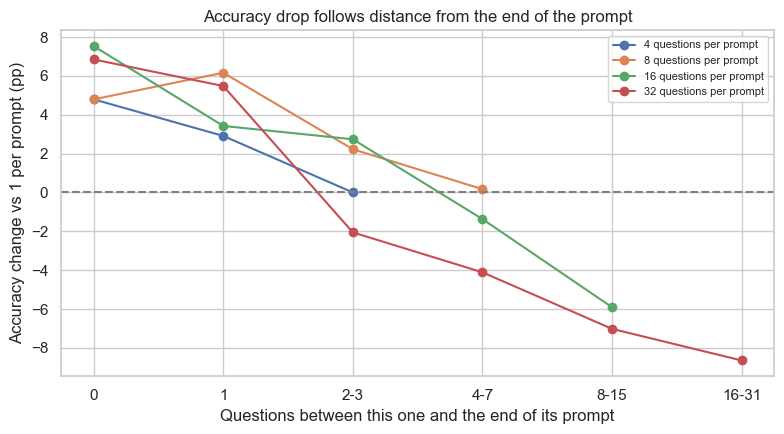

In [8]:
import warnings
from scipy.stats import chi2
from statsmodels.discrete.conditional_models import ConditionalLogit

# 每題在「自己那份 prompt」裡是第幾題:frozen request 的 field_ids 順序就是 prompt 裡 Q1、Q2… 的順序
local = {}
for e in ["E1", "E2", "E3", "E4", "E5"]:
    with gzip.open(f"data/frozen_requests/{e}.jsonl.gz", "rt") as f:
        for line in f:
            r = json.loads(line)
            for i, fid in enumerate(r["field_ids"]):
                local[(e, r["report_id"], fid)] = (i + 1, len(r["field_ids"]))

P = S7.copy()
P[["local", "size"]] = [local[k] for k in zip(P.experiment, P.report_id, P.field_id)]
P["from_end"] = P["size"] - P["local"]                          # 0 = prompt 的最後一題
P["q"] = P.report_id + "|" + P.field_id                         # 題目 id(固定效果的分組)
assert len(P) == 5 * 2336

SIZE = pd.get_dummies(P["size"].astype(str), prefix="size", drop_first=True).astype(float)[["size_4", "size_8", "size_16", "size_32"]]

def fit(df, pos=None, size=SIZE):
    """條件式 logistic:對錯 ~ 批次大小 + 位置,題目固定效果(同一題跟自己比)"""
    X = size.loc[df.index].copy()
    if pos is not None:
        X = X.join(pos.loc[df.index].rename("pos") if isinstance(pos, pd.Series) else pos.loc[df.index])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                         # 五次全對/全錯的題沒有題內變化,會被丟掉並警告
        return ConditionalLogit(df.y, X, groups=df.q.loc[df.index]).fit(disp=0)

# 1. 位置的幾種寫法,比 AIC(越小越貼近資料)
specs = {
    "batch size only": None,
    "relative position (0=first, 1=last)": (P.local - 1) / (P["size"] - 1).clip(lower=1),
    "questions from start (= from end, linear)": P.from_end.astype(float),
    "not in last 8 (0/1)": (P.from_end >= 8).astype(float),
    "log2(questions from end + 1)": np.log2(P.from_end + 1),
}
aic = {k: fit(P, v) for k, v in specs.items()}
print(pd.DataFrame({"AIC": {k: -2 * m.llf + 2 * len(m.params) for k, m in aic.items()},
                    "OR batch 32": {k: np.exp(m.params["size_32"]) for k, m in aic.items()}}).round(2).to_string())

# 2. 主模型:log2(離結尾幾題 + 1);區間用「整份報告重抽」的 bootstrap,因為同一份報告的題目不獨立
P["pos"] = np.log2(P.from_end + 1)
main = aic["log2(questions from end + 1)"]
reports = P.report_id.unique()
by_rep = {r: P.index[P.report_id == r] for r in reports}
rng = np.random.default_rng(0)
boot = []
for _ in range(200):                                            # 每次重抽都要重新擬合,200 次約 3 分鐘
    pick = rng.choice(reports, len(reports))
    idx = np.concatenate([by_rep[r] for r in pick])
    B = P.loc[idx].reset_index(drop=True)
    B["q"] = B.q + "#" + np.repeat(np.arange(len(pick)), [len(by_rep[r]) for r in pick]).astype(str)  # 同一份報告被抽到兩次 = 兩組不同的題
    Xb = SIZE.loc[idx].reset_index(drop=True).assign(pos=B.pos)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        boot.append(ConditionalLogit(B.y, Xb, groups=B.q).fit(disp=0).params.values)
boot = np.exp(np.array(boot))
OR = pd.DataFrame({"OR": np.exp(main.params),
                   "lo": np.percentile(boot, 2.5, axis=0), "hi": np.percentile(boot, 97.5, axis=0)}, index=main.params.index)
print("Main model, odds ratios vs E1 [95% CI, bootstrap over", len(reports), "reports]")
print(OR.round(3).to_string())

# 3. 位置效果在 16 題和 32 題的 prompt 裡一樣嗎?(加交互作用,概似比檢定)
inter = SIZE.assign(pos=P.pos, pos_x32=P.pos * (P["size"] == 32))
m_int = fit(P, size=inter)
lr = 2 * (m_int.llf - main.llf)
print(f"Position slope differs for 32 vs other sizes? OR ratio = {np.exp(m_int.params['pos_x32']):.2f}, LR chi2 = {lr:.2f}, p = {chi2.sf(lr, 1):.2f}")

# 4. 圖:相對 E1 的準確率變化,依「離結尾幾題」分組,每個批次大小一條線
E1 = P[P.experiment == "E1"].set_index("q").y
D = P[P.experiment != "E1"].assign(d=lambda x: x.y - x.q.map(E1).values)
bins = [-1, 0, 1, 3, 7, 15, 31]
labels = ["0", "1", "2-3", "4-7", "8-15", "16-31"]
D["bin"] = pd.cut(D.from_end, bins, labels=labels)
G = D.groupby(["size", "bin"], observed=True).d.agg(["mean", "count"]).reset_index()
print(G.assign(mean=lambda x: (x["mean"] * 100).round(1)).pivot(index="bin", columns="size", values="mean").to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for s, g in G.groupby("size"):
    ax.plot(g.bin.astype(str), g["mean"] * 100, marker="o", label=f"{s} questions per prompt")
ax.axhline(0, color="gray", ls="--")
ax.set(xlabel="Questions between this one and the end of its prompt", ylabel="Accuracy change vs 1 per prompt (pp)",
       title="Accuracy drop follows distance from the end of the prompt")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("figures/error_a3_position.png", dpi=150); plt.show()


- **位置的寫法**:log2(離結尾幾題 + 1) 的 AIC 最低(5108.6),比「不在最後 8 題」(5115.5)、「相對位置」(5121.4)、只放批次大小(5137.8)都好。直線的「從開頭數第幾題」和「離結尾幾題」AIC 相同,因為批次大小已在模型裡,兩者只差一個常數;要用非線性寫法才分得出是「靠近結尾」。
- **主結果**:離結尾的距離每變成兩倍,答對的勝算變成 0.81 倍(95% 區間 0.75–0.87)。
- **控制位置後,批次大小沒有額外的直接影響**:批次 32 題相對 E1 的勝算比是 1.35(0.95–1.93),4 / 8 / 16 題是 1.45 / 1.71 / 1.52,區間都在 1 以上。也就是說,同樣是 prompt 的最後一題,放在批次裡反而比一題一問好。
- **位置效果在 32 題和其他批次大小一樣**:交互作用的勝算比 0.98,概似比檢定 p = 0.75。
- **圖**:同樣離結尾幾題時,四種批次大小的變化量接近。最後一題 +5 ~ +8 pp;離結尾 8–15 題時,16 題和 32 題的 prompt 分別是 −5.9 和 −7.0 pp。
- **解讀**:批次大小仍是根因,但它透過位置起作用:批次變大 → prompt 變長 → 多數題目離結尾變遠 → 準確率下降。位置是中介變數,不是另一個獨立原因。
- 限制:(1) 「離結尾近」和「離輸出格式說明近」、「離模型開始寫答案的地方近」在這份資料裡是同一件事,分不開;(2) 離結尾 8 題以上只出現在 E4、E5,小批次「如果離結尾遠也會變差」是模型的推論,不是直接觀察;(3) 「批次裡的最後幾題比一題一問好」的原因不清楚;(4) 題序從沒打亂過,仍是相關;要確認因果需要反轉題序重跑;(5) 圖中每個點的題數不同,離結尾 0 題那一點每個條件只有 73–584 題,較不穩。

# B. 錯的時候錯在哪

## B1 錯誤很穩定,不是碰運氣

對應 [error_analysis.md](error_analysis.md) B1。
同一批 2,336 題(`matched_localization=True`)在 E1–E5 各回答一次,選項與正確字母都相同(已核對每題的 `target` 在五個條件下一致)。問題:答錯是每次碰運氣,還是同一題反覆錯?

兩個檢查,各有一個明確的「亂猜」虛無假設:
1. **同一題的對錯是否彼此獨立?** 排列檢定:把每個條件的對錯向量在題目之間隨機洗牌(每個條件的準確率不變,但「哪些題答對」變隨機),重複 2000 次。統計量 = 五次全錯的題數。若實際遠大於洗牌後的分布,代表錯誤集中在特定題目。
2. **全錯的題目,錯的是同一個選項嗎?** 虛無假設:每次在 4 個錯誤選項中均勻亂選。五次選擇的「不同字母數」分布可以精確算出;用二項檢定比較「五次都選同一個」的題數。

Correct count 0..5, observed: [821, 504, 344, 278, 225, 164]
Correct count 0..5, expected if independent: [336, 798, 756, 355, 83, 8]
All-wrong questions: 821 vs 336 expected, permutation p <= 0.0005


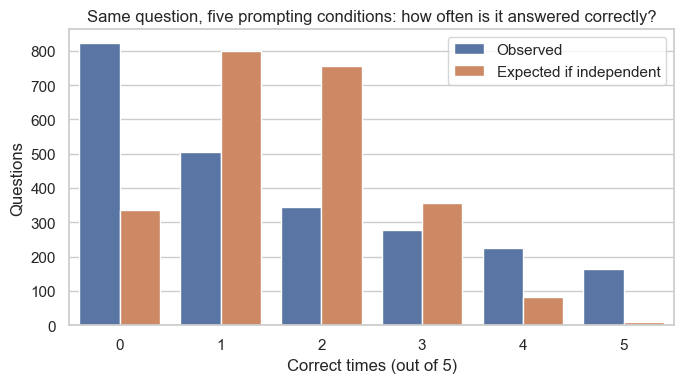

All-wrong questions: 821; picked the same wrong letter all 5 times: 162 (expected 3 if random), p = 2.4e-216


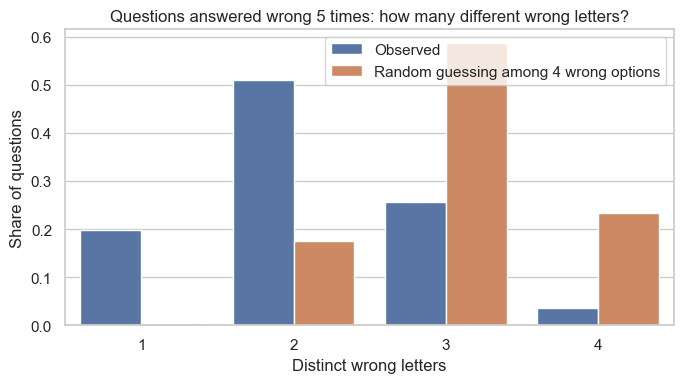

In [9]:
from scipy.stats import binomtest
from itertools import product

S = pd.read_csv("data/per_field.csv")
S = S[(S.category == "fine_grained_action_localization") & S.matched_localization & S.experiment.isin(["E1", "E2", "E3", "E4", "E5"])]
C = S.pivot(index=["report_id", "field_id"], columns="experiment", values="correct")  # 題 x 條件
n_right = C.sum(axis=1)

# 檢查 1:排列檢定(每個條件獨立洗牌)
rng = np.random.default_rng(0)
M = C.values
perm_counts = np.zeros((2000, 6))
for i in range(2000):
    sh = np.column_stack([rng.permutation(M[:, j]) for j in range(5)])
    perm_counts[i] = np.bincount(sh.sum(axis=1), minlength=6)
obs = np.bincount(n_right, minlength=6)
p_all_wrong = (np.sum(perm_counts[:, 0] >= obs[0]) + 1) / (2000 + 1)
print("Correct count 0..5, observed:", obs.tolist())
print("Correct count 0..5, expected if independent:", perm_counts.mean(axis=0).round(0).astype(int).tolist())
print(f"All-wrong questions: {obs[0]} vs {perm_counts[:, 0].mean():.0f} expected, permutation p <= {p_all_wrong:.4f}")

cnt = pd.DataFrame({"Correct times (out of 5)": list(range(6)) * 2,
                    "Questions": list(obs) + list(perm_counts.mean(axis=0)),
                    "": ["Observed"] * 6 + ["Expected if independent"] * 6})
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cnt, x="Correct times (out of 5)", y="Questions", hue="", ax=ax)
ax.set_title("Same question, five prompting conditions: how often is it answered correctly?")
plt.tight_layout(); plt.show()

# 檢查 2:全錯的題目,五次選了幾種不同的錯誤字母
allwrong = C.index[n_right == 0]
pred = S.set_index(["report_id", "field_id"]).loc[allwrong].groupby(level=[0, 1]).predicted
k_obs = pred.nunique().value_counts().reindex([1, 2, 3, 4], fill_value=0)

# 虛無假設:5 次各自在 4 個錯誤選項中均勻亂選 -> 精確分布
null = pd.Series([len(set(s)) for s in product(range(4), repeat=5)]).value_counts(normalize=True).sort_index()
t = binomtest(int(k_obs[1]), len(allwrong), null[1])
print(f"All-wrong questions: {len(allwrong)}; picked the same wrong letter all 5 times: {k_obs[1]} "
      f"(expected {null[1]*len(allwrong):.0f} if random), p = {t.pvalue:.2g}")

dist = pd.DataFrame({"Distinct wrong letters": [1, 2, 3, 4] * 2,
                     "Share of questions": list(k_obs / len(allwrong)) + list(null),
                     "": ["Observed"] * 4 + ["Random guessing among 4 wrong options"] * 4})
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=dist, x="Distinct wrong letters", y="Share of questions", hue="", ax=ax)
ax.set_title("Questions answered wrong 5 times: how many different wrong letters?")
plt.tight_layout(); plt.show()

- 同一題答對次數的分布兩端特別多:五次全錯 821 題,獨立情況下只期望 336 題(排列檢定 p ≤ 0.0005,2000 次洗牌沒有一次達到);五次全對 164 題,期望 8 題。同一題的對錯高度相關,難易主要由題目決定,不是每次碰運氣。
- 五次全錯的 821 題裡,有 162 題五次選了同一個錯誤字母,亂選只期望約 3 題(二項檢定 p ≈ 2e-216);只選 1–2 種字母的合計佔 71%,亂選只有約 18%。錯誤集中在特定的錯誤選項。
- 所以可以拒絕兩個「亂打」假設:(1) 各次對錯互相獨立;(2) 答錯時均勻亂選錯誤選項。
- 限制:(1) 五個條件共用同一支影片與選項,不是五次獨立實驗,第 1 個檢定證明的是「題目有難易之分」,不是模型有固定的錯誤想法;(2) 第 2 個檢定的基準是均勻亂選,但 B3、B4 已證明模型對長選項、對特定字母有偏好,這些共同偏好也會讓不同次選到同一個選項,所以「被某個錯誤選項吸引」不能全歸因於題目內容;(3) p 值極小只表示偏離明確,不代表效果大小,看圖比看 p 值有用。

## B2 錯得多遠,選到什麼

對應 [error_analysis.md](error_analysis.md) B2。
前 4 點問「什麼情況容易錯」,這一點問「錯在哪」:是時間點差一點,還是選到完全不同的動作?

**距離怎麼算**:選中的錯誤選項和正確選項,兩個時段中點相差幾秒。
- 因為每題給模型看的影片長度不同(約 205–886 秒,中位數約 500 秒),除了秒數,也算 **相對距離 = 距離 ÷ 該題影片長度**。
- 分母是 `videos[0]` 的 `end_s - start_s`,也就是模型實際看到的那段影片,不是整支原始影片(原始總長沒有存在資料裡)。選項的時間戳是相對這段影片的,全部都落在 0 ~ 影片長度內。

**檢查**:
1. 描述:答錯時的距離分布(秒數、相對距離)。
2. 對照基準:同一題 4 個錯誤選項,如果模型隨機挑,每個被選中機率 25%。比較「被選中的是不是離正解最近的那個」(二項檢定,虛無假設 25%),這回答「模型是否因為『時間接近』而選它」。
3. 干擾選項的來源:有多少錯誤選項剛好是同一份報告裡另一題的正確時段(= 真實發生過的動作)。

1933 wrong answers; video length median 498s
Distance to truth: median 33.5s, within 5s 19%, over 60s 36%
Relative distance: median 7.0% of video length, within 2% 29%, over 20% 24%
Picked the closest wrong option: 582/1933 = 30.1%, p = 3.9e-07 (chance 25%)
Wrong options that are another question's true segment: 35%


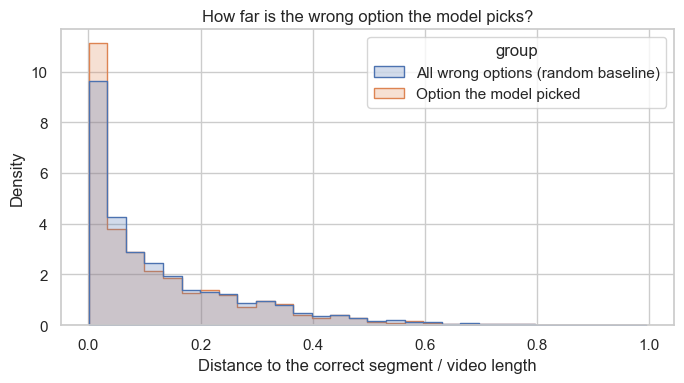

In [10]:
from scipy.stats import binomtest

# 每題:5 個選項的中點、影片長度(模型實際看到的那段)
def sec(t):
    h, m, s = t.split(":"); return int(h) * 3600 + int(m) * 60 + float(s)

info = {}
with gzip.open("data/frozen_requests/E1.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line)
        o = re.findall(r"^([A-E])\. (this clip from [\d:.]+ to ([\d:.]+))", r["user"], re.M)
        if len(o) != 5: continue
        o = {k: (txt, sec(txt.split()[3]), sec(end)) for k, txt, end in o}   # 文字、起、迄
        v = r["videos"][0]
        info[r["call_id"]] = dict(mid={k: (a + b) / 2 for k, (_, a, b) in o.items()},
                                  txt={k: t for k, (t, _, _) in o.items()},
                                  clip=v["end_s"] - v["start_s"])

F = pd.read_csv("data/per_field.csv")
F = F[(F.experiment == "E1") & (F.category == "fine_grained_action_localization") & F.call_id.isin(info)]
gold_txt = F.groupby("report_id").target_text.apply(set)       # 同一份報告裡所有題目的正確時段

rows = []
for r in F[~F.correct].itertuples():
    q = info[r.call_id]
    dist = {k: abs(m - q["mid"][r.target]) for k, m in q["mid"].items() if k != r.target}  # 4 個錯誤選項
    ranks = sorted(dist, key=dist.get)
    others = gold_txt[r.report_id] - {r.target_text}
    rows.append(dict(chosen=dist[r.predicted], rel=dist[r.predicted] / q["clip"],
                     closest=ranks[0] == r.predicted,
                     all_dist=list(dist.values()), all_rel=[x / q["clip"] for x in dist.values()],
                     real=[q["txt"][k] in others for k in dist]))
W5 = pd.DataFrame(rows)

print(f"{len(W5)} wrong answers; video length median {np.median([q['clip'] for q in info.values()]):.0f}s")
print(f"Distance to truth: median {W5.chosen.median():.1f}s, within 5s {(W5.chosen <= 5).mean():.0%}, over 60s {(W5.chosen > 60).mean():.0%}")
print(f"Relative distance: median {W5.rel.median():.1%} of video length, within 2% {(W5.rel <= .02).mean():.0%}, over 20% {(W5.rel > .2).mean():.0%}")
k = int(W5.closest.sum())
print(f"Picked the closest wrong option: {k}/{len(W5)} = {k/len(W5):.1%}, p = {binomtest(k, len(W5), 0.25).pvalue:.2g} (chance 25%)")
print(f"Wrong options that are another question's true segment: {np.mean([x for r in W5.real for x in r]):.0%}")

# 圖:被選中的錯誤選項 vs 所有錯誤選項(隨機挑的基準)的相對距離分布
base = pd.DataFrame({"rel": [x for r in W5.all_rel for x in r], "group": "All wrong options (random baseline)"})
pick = pd.DataFrame({"rel": W5.rel, "group": "Option the model picked"})
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(pd.concat([base, pick]), x="rel", hue="group", stat="density", common_norm=False,
             element="step", bins=30, ax=ax)
ax.set(xlabel="Distance to the correct segment / video length", ylabel="Density",
       title="How far is the wrong option the model picks?")
plt.tight_layout(); plt.show()

- 答錯時選到的片段離正解中位數 33.5 秒(約影片長度的 7%);只有 19% 在 5 秒內,36% 超過 60 秒。和報告一致。這不是「差一點」。
- 對照基準:4 個錯誤選項本身離正解的中位數是 38.4 秒(8.0%)。模型選的只比隨機挑稍近一點,直方圖上兩條分布幾乎重疊。
- 「選到離正解最近的錯誤選項」佔 30.1%,高於隨機的 25%(二項檢定 p ≈ 4e-7)。有「靠近正解」的傾向,但效果很小(多 5 個百分點),大多數錯誤仍是選到遠處的選項。
- 35% 的錯誤選項正好是同一份報告裡另一題的正確時段(報告為 34%,差別應是比對細節),說明干擾選項多半是真實發生過的動作。
- 限制:(1) 沒有比較「真實動作的干擾」和「非真實動作的干擾」哪個更容易被選中,所以不能說是因為它真實才被選;(2) 相對距離的分母是模型實際看到的片段長度,不是整支原始影片;(3) p 值假設每題獨立,偏樂觀。

## B3 偏好最長的選項

對應 [error_analysis.md](error_analysis.md) B3。

資料來源:選項時段只存在 `data/frozen_requests/E1.jsonl.gz` 的 `user`(prompt)裡,
模型選擇與正解來自 `data/per_field.csv` 的 `predicted` / `target`,用 `call_id` 對應。

- 檢查 1:所有題目中,模型選中最長選項的比例,基準 20%(5 選 1)。
- 檢查 2:只看答錯的題,在 4 個錯誤選項裡選中最長者的比例,基準 25%。
- 統計檢定:單一比例的二項檢定(binomial test),不需要更複雜的方法。
- 並列最長時,只要長度等於最大值就算「最長」。

Check 1: picked longest 787/2861 = 27.5%, p = 5.4e-22 (chance 20%)
Check 2: among wrong answers picked longest wrong option 602/1933 = 31.1%, p = 1.2e-09 (chance 25%)


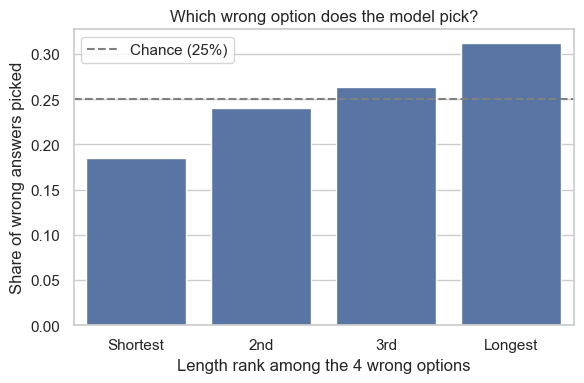

In [11]:
import gzip, json
from scipy.stats import binomtest

def sec(t):
    h, m, s = t.split(":"); return int(h) * 3600 + int(m) * 60 + float(s)

opt_len = {}
with gzip.open("data/frozen_requests/E1.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line)
        o = re.findall(r"^([A-E])\. this clip from ([\d:.]+) to ([\d:.]+)", r["user"], re.M)
        if len(o) == 5:
            opt_len[r["call_id"]] = {k: sec(b) - sec(a) for k, a, b in o}

L = pd.read_csv("data/per_field.csv")
L = L[(L.experiment == "E1") & (L.category == "fine_grained_action_localization")]
L = L[L.call_id.isin(opt_len)].copy()
L["pick_longest"] = [opt_len[c][p] == max(opt_len[c].values()) for c, p in zip(L.call_id, L.predicted)]

# 檢查 1:全部題目
n, k = len(L), int(L.pick_longest.sum())
print(f"Check 1: picked longest {k}/{n} = {k/n:.1%}, p = {binomtest(k, n, 0.2).pvalue:.2g} (chance 20%)")

# 檢查 2:只看答錯,依長度把 4 個錯誤選項排名 (0 = 最短 ... 3 = 最長)
W = L[~L.correct]
def wrong_rank(row):
    wrong = sorted((v, k_) for k_, v in opt_len[row.call_id].items() if k_ != row.target)
    return [k_ for _, k_ in wrong].index(row.predicted)
W = W.assign(rank=W.apply(wrong_rank, axis=1))
k2 = int((W["rank"] == 3).sum())
print(f"Check 2: among wrong answers picked longest wrong option {k2}/{len(W)} = {k2/len(W):.1%}, "
      f"p = {binomtest(k2, len(W), 0.25).pvalue:.2g} (chance 25%)")

share = W["rank"].value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Shortest", "2nd", "3rd", "Longest"], y=share.values, color=sns.color_palette("deep")[0], ax=ax)
ax.axhline(0.25, ls="--", color="gray", label="Chance (25%)")
ax.set(xlabel="Length rank among the 4 wrong options", ylabel="Share of wrong answers picked",
       title="Which wrong option does the model pick?")
ax.legend(); plt.tight_layout(); plt.show()

- 如果模型答錯時完全隨機挑錯誤選項,1933 題裡選中最長者 602 題以上(31.1% 或更高)的機率約十億分之一。這不是「模型有偏好」的機率,而是「隨機會產生這種結果」的機率。兩者不同,但前者小到可以拒絕隨機的假設
- 檢定只證明答錯時,模型挑錯誤選項不是均勻隨機的,模型會偏向長的選項。 它排除了運氣,但沒有排除其他原因。例如最長的選項可能剛好更容易被選中,是因為它通常也是離正確答案時間最近的選項。這需要另外檢查

## B4 字母位置偏差

對應 [error_analysis.md](error_analysis.md) B4。
資料全部來自 `data/per_field.csv`(`predicted`、`target` 兩欄),只看定位題,E1–E5 各條件分開算。

兩個檢查:
1. **模型選擇的字母分布 vs 標準答案的字母分布**:卡方適合度檢定(`chisquare`)。虛無假設 = 模型選字母的比例和標準答案一樣(沒有字母偏好)。
2. **E1 單一字母是否被偏愛**:對 B 做二項檢定,虛無假設 = 選 B 的機率等於標準答案是 B 的比例(約 20%)。

注意:這裡只能說「模型選擇的分布和標準答案不同」,不能說原因是字母本身;選項順序沒有被打亂過,字母位置和選項內容綁在一起(見 B3 的討論)。

E1: chi2 = 126, p = 3.5e-26
E2: chi2 = 22, p = 0.00024
E3: chi2 = 37, p = 2.1e-07
E4: chi2 = 24, p = 8.9e-05
E5: chi2 = 24, p = 9e-05
E1 picks B: 776/2861 = 27.1%, p = 4.5e-22 (gold share of B = 19.6%)


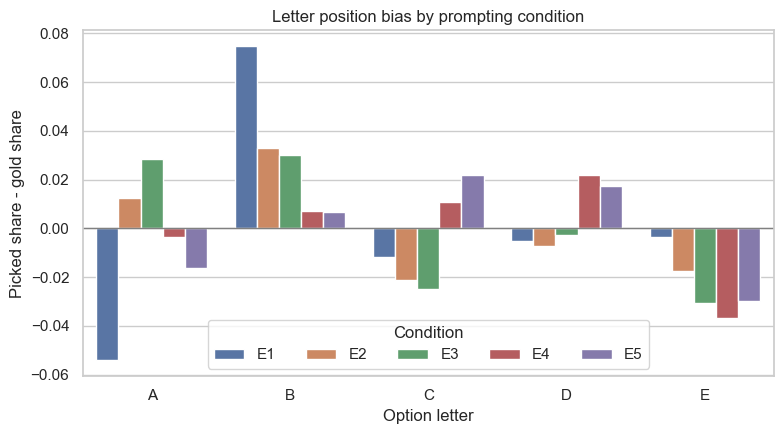

In [12]:
from scipy.stats import chisquare, binomtest

P = pd.read_csv("data/per_field.csv")
P = P[(P.category == "fine_grained_action_localization") & P.experiment.isin(["E1", "E2", "E3", "E4", "E5"])]
letters = list("ABCDE")

pred = P.groupby("experiment").predicted.value_counts(normalize=True).unstack()[letters]
gold = P[P.experiment == "E1"].target.value_counts(normalize=True)[letters]  # 標準答案分布(各條件題目相同或近似)

# 檢查 1:每個條件的預測分布 vs 標準答案分布
for e, g in P.groupby("experiment"):
    obs = g.predicted.value_counts()[letters].values
    exp = g.target.value_counts(normalize=True)[letters].values * len(g)
    stat, p = chisquare(obs, exp)
    print(f"{e}: chi2 = {stat:.0f}, p = {p:.2g}")

# 檢查 2:E1 選 B 的次數
e1 = P[P.experiment == "E1"]
kB = int((e1.predicted == "B").sum())
print(f"E1 picks B: {kB}/{len(e1)} = {kB/len(e1):.1%}, p = {binomtest(kB, len(e1), gold['B']).pvalue:.2g} "
      f"(gold share of B = {gold['B']:.1%})")

# 圖:模型選擇比例 - 標準答案比例(0 = 沒有偏差)
diff = (pred - gold).reset_index().melt(id_vars="experiment", var_name="letter", value_name="diff")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=diff, x="letter", y="diff", hue="experiment", ax=ax)
ax.axhline(0, color="gray", lw=1)
ax.set(xlabel="Option letter", ylabel="Picked share - gold share",
       title="Letter position bias by prompting condition")
ax.legend(title="Condition", ncol=5, loc="lower center")
plt.tight_layout(); plt.show()

#### 檢查 1(卡方,E1–E5):字母偏差存在,而且會隨提問方式改變。

- 五個條件的 p 都遠小於 0.001(最大是 E2 的 2.4e-4),所以每個條件都能拒絕「模型選字母和標準答案分布一樣」。
- 一題一問的 E1 卡方值是 126,批次的 E2–E5 只有 22–37,所以 E1 的偏離最大。
- 這代表模型選字母不是中立的。但這個檢定只說「有偏離」,沒說偏向哪個字母。

#### 檢查 2(二項,E1 的 B):一題一問時,模型明顯偏愛 B。

- 模型選 B 的比例是 27.1%(776/2861),標準答案是 B 的比例只有 19.6%,p = 4.5e-22。
- 這個偏愛幅度約 7.5 個百分點,效果不小。
- 這個結論只適用於 E1。批次條件下 B 的偏好消失了,改成少選 E。

#### 限制
- p 值假設每題獨立;同一支影片的題目彼此相關,所以 p 偏樂觀。重點看卡方的相對大小和圖,不要只看 p。
- 只能說「有字母偏差、會隨提問方式改變」;要確認是字母造成,需要打亂選項順序重跑(報告的後續實驗)。